<div style="
background:linear-gradient(135deg,#171922,#10131b);
border:2px solid #3ce7e7;
border-radius:22px;
padding:32px;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Arial,sans-serif;
color:white;
box-shadow:0 0 18px rgba(60,231,231,.18);
">

<div style="display:flex;align-items:center;gap:14px;">
<span style="font-size:34px;">👨‍💻</span>

<div>
<div style="
font-size:34px;
font-weight:800;
color:#4ff5f5;
text-shadow:0 0 8px rgba(79,245,245,.35);
">
Aliakbar Isapour
</div>

<div style="
color:#bfbfbf;
font-size:16px;
margin-top:3px;
">
Machine Learning • Data Science • AI
</div>
</div>
</div>

<div style="
height:2px;
background:linear-gradient(90deg,#7b3ff2,#4ff5f5);
border-radius:5px;
margin:22px 0;
"></div>

<div style="
color:#d7d7d7;
font-size:16px;
line-height:1.7;
margin-bottom:25px;
">

</div>


<div style="display:flex;gap:14px;flex-wrap:wrap;">

<a href="https://github.com/isapour0"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
GitHub
</a>

<a href="https://www.linkedin.com/in/aliakbar-isapour-682592413"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
LinkedIn
</a>


</div>

</div>

## About Dataset
This data was extracted from the 1994 Census bureau database by Ronny Kohavi and Barry Becker (Data Mining and Visualization, Silicon Graphics). A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && (AGI>100) && (AFNLWGT>1) && (HRSWK>0)). The prediction task is to determine whether a person makes over $50K a year.

## Description of fnlwgt (final weight)
The weights on the Current Population Survey (CPS) files are controlled to independent estimates of the civilian noninstitutional population of the US. These are prepared monthly for us by Population Division here at the Census Bureau. We use 3 sets of controls. These are:

A single cell estimate of the population 16+ for each state.

Controls for Hispanic Origin by age and sex.

Controls by Race, age and sex.

We use all three sets of controls in our weighting program and "rake" through them 6 times so that by the end we come back to all the controls we used. The term estimate refers to population totals derived from CPS by creating "weighted tallies" of any specified socio-economic characteristics of the population. People with similar demographic characteristics should have similar weights. There is one important caveat to remember about this statement. That is that since the CPS sample is actually a collection of 51 state samples, each with its own probability of selection, the statement only applies within state.

## Dataset
- Source: Becker, B. & Kohavi, R. (1996). Adult [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20
- File: `data/raw/adult.csv` (not tracked by git)
- Target: `income` (`<=50K` or `>50K`)
- Features: 14 columns, for example `age`, `workclass`, `education`, `occupation`, `hours.per.week`

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📌 Library Imports</h2>
<hr style="border:1px solid #8A2BE2; opacity:.4;">
</div>

In [41]:
# ---- core ----
import time
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import sys

# ---- visualisation ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- preprocessing ----
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
import sklearn
import xgboost

# ---- model ----
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier

# ---- metrics ----
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.base import clone

# ---- Config ----
RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/adult.csv")   # notebook lives in notebooks/
TARGET = "income"

sns.set_theme(style="darkgrid")
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
    
<h2 style="color:#00E5FF;">📂 Data Loding & Initial review</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1: Data loading.</li>
<li>Step 2: Initial review.</li>
</ul>

</div>


In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(df.shape)
df.head()

(32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
# Dtpe Columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [4]:
df.shape

(32561, 15)

In [5]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

In [6]:
df['income'].value_counts()

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [7]:
# Descriptive Statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education.num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital.status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
def question(data):

    data[data == '?'] = np.nan

    print("Duplicate rows:", data.duplicated().sum())
    print ('------------------')
    print(data.isna().sum().sort_values(ascending=False).head(15))

    return data

question = question(df)

Duplicate rows: 24
------------------
occupation        1843
workclass         1836
native.country     583
fnlwgt               0
education            0
education.num        0
age                  0
marital.status       0
relationship         0
sex                  0
race                 0
capital.gain         0
capital.loss         0
hours.per.week       0
income               0
dtype: int64


In [9]:
text_cols = df.select_dtypes(exclude="number").columns

text_check = pd.DataFrame({
    "question_marks": (df[text_cols] == "?").sum(),
    "extra_spaces": df[text_cols].apply(lambda s: (s != s.str.strip()).sum()),
    "unique_values": df[text_cols].nunique(),
})
text_check

,question_marks,extra_spaces,unique_values
workclass,0,1836,8
education,0,0,16
marital.status,0,0,7
occupation,0,1843,14
relationship,0,0,6
race,0,0,5
sex,0,0,2
native.country,0,583,41
income,0,0,2


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔧 Data Cleaning</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1: turn "?" into real missing values</li>
<li>Step 2: drop exact duplicate rows.</li>
<li>Step 3: drop `fnlwgt` (a survey sampling weight, not a property of the person).</li>
<li>Step 4: quick sanity checks.</li>
</ul>
</div>


In [10]:
# Step 1: turn "?" into real missing values
df = df_raw.replace("?", np.nan)     # df_raw stays untouched

missing = df.isna().sum()
print(missing[missing > 0])
print("Remaining '?':", (df == "?").sum().sum())

workclass         1836
occupation        1843
native.country     583
dtype: int64
Remaining '?': 0


In [11]:
# Step 2: drop exact duplicate rows.
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(df)} duplicate rows -> {len(df)} rows left")

Removed 24 duplicate rows -> 32537 rows left


In [12]:
# Step 3: drop `fnlwgt` (a survey sampling weight, not a property of the person).
DROP_COLS = ["fnlwgt"]
df = df.drop(columns=DROP_COLS)
print(df.shape)

(32537, 14)


In [13]:
miss_cols = ["workclass", "occupation", "native.country"]
high = (df[TARGET] == ">50K")

print("Rows with at least one NaN:", df[miss_cols].isna().any(axis=1).sum())

rate = pd.DataFrame({c: high.groupby(df[c].isna()).mean() for c in miss_cols})
rate = rate.rename(index={False: "not missing", True: "missing"}).round(3)
rate

Rows with at least one NaN: 2398


,workclass,occupation,native.country
not missing,0.249,0.249,0.241
missing,0.104,0.104,0.251


In [14]:
# Step 4: quick sanity checks.

# education vs education.num: one-to-one mapping? (1 and 1 means yes)
print(df.groupby("education")["education.num"].nunique().max(),
      df.groupby("education.num")["education"].nunique().max())

# the value we flagged in capital.gain
top = df[df["capital.gain"] == 99999]
print("Rows with capital.gain == 99999:", len(top))
print(top[TARGET].value_counts())

1 1
Rows with capital.gain == 99999: 159
income
>50K    159
Name: count, dtype: int64


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📊 EDA</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1: which features are most related to `income`?</li>
<li>Step 2: how skewed are `capital.gain` and `capital.loss`, and what does the suspicious value 99999 look like?</li>
</ul>
</div>

In [15]:
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

y_bin = (df[TARGET] == ">50K").astype(int)       # 1 = high income
numeric_cols = ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
cat_cols = ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

COLORS = {"<=50K": "#4C72B0", ">50K": "#DD8452"}  # colour-blind friendly pair

print(df.shape)
print(numeric_cols)
print(cat_cols)

(32537, 14)
['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


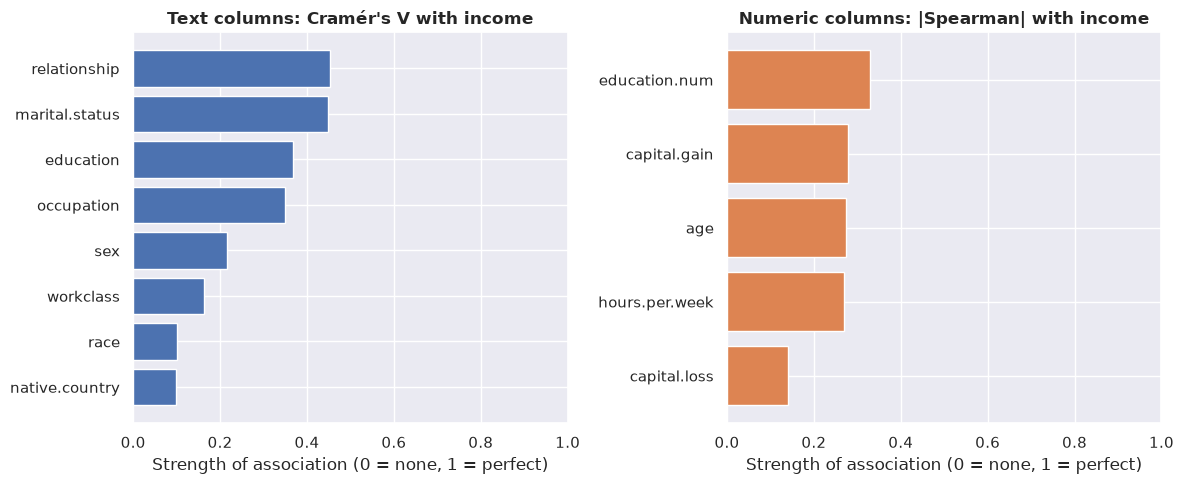

relationship      0.454
marital.status    0.447
education         0.369
occupation        0.349
sex               0.216
workclass         0.164
race              0.101
native.country    0.099
dtype: float64
education.num     0.330
capital.gain      0.278
age               0.273
hours.per.week    0.269
capital.loss      0.141
dtype: float64


In [16]:
# The impact of each feature on the target

from scipy.stats.contingency import association

def cramers_v(a, b):
    return association(pd.crosstab(a, b), method="cramer")

v_text = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in cat_cols}).sort_values()
r_num = pd.Series(
    {c: abs(df[c].corr(y_bin, method="spearman")) for c in numeric_cols}
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(v_text.index, v_text.values, color="#4C72B0")
axes[0].set_title("Text columns: Cramér's V with income", fontweight="bold")
axes[1].barh(r_num.index, r_num.values, color="#DD8452")
axes[1].set_title("Numeric columns: |Spearman| with income", fontweight="bold")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_xlabel("Strength of association (0 = none, 1 = perfect)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_association_with_income.png", dpi=150, bbox_inches="tight")
plt.show()

print(v_text.sort_values(ascending=False).round(3))
print(r_num.sort_values(ascending=False).round(3))

**Figure 1.** Among text columns, `relationship` and `marital.status` have the strongest
association with `income`, followed by `education` and `occupation`; `race` and
`native.country` are the weakest. Among numeric columns `education.num` is highest and
`capital.loss` lowest. The two panels use different measures and are not comparable.

Overall high-income rate: 0.241


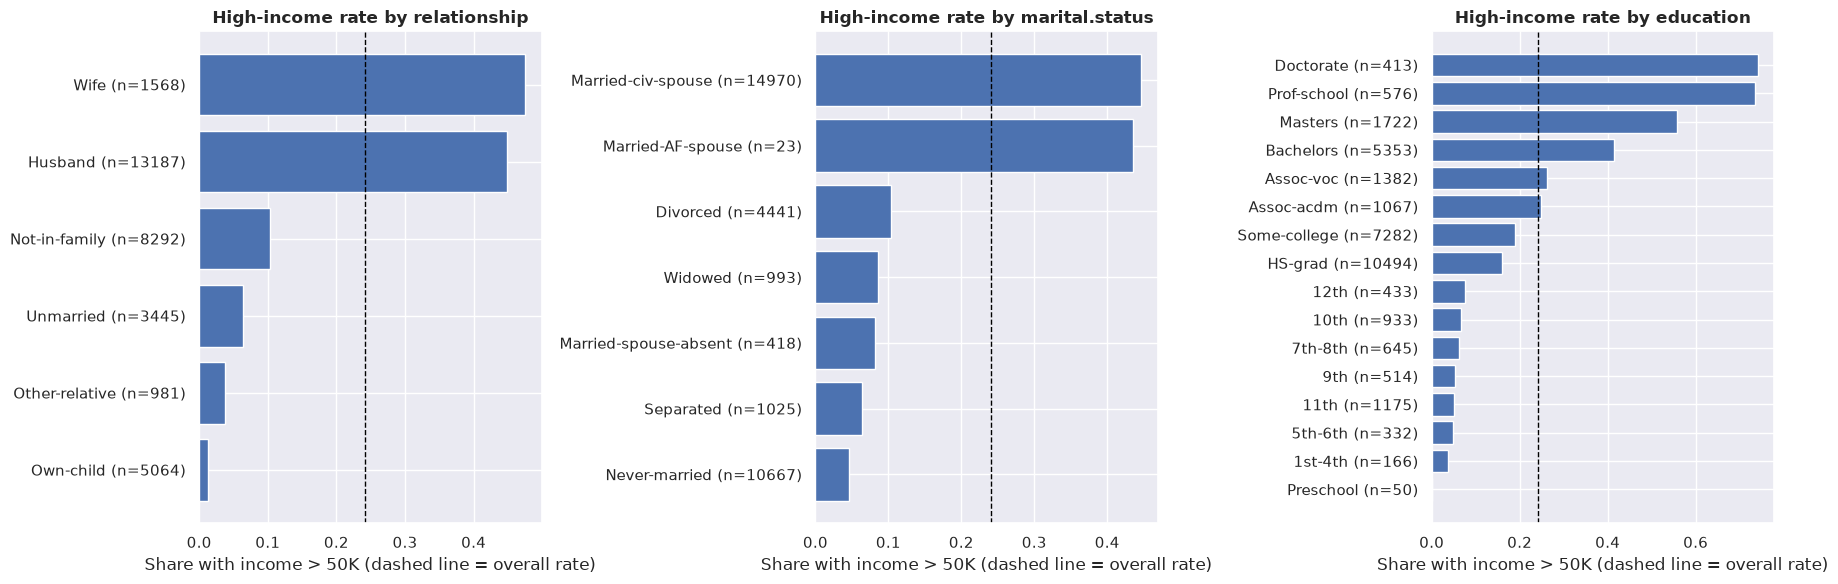

In [17]:
top3 = v_text.sort_values(ascending=False).head(3).index.tolist()
base_rate = y_bin.mean()
print(f"Overall high-income rate: {base_rate:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, top3):
    col = df[c].fillna("Unknown")                 # display only, df is not changed
    counts = col.value_counts()
    rate = y_bin.groupby(col).mean().sort_values()
    labels = [f"{k} (n={counts[k]})" for k in rate.index]
    ax.barh(labels, rate.values, color="#4C72B0")
    ax.axvline(base_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"High-income rate by {c}", fontweight="bold")
    ax.set_xlabel("Share with income > 50K (dashed line = overall rate)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_income_rate_top_categories.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2.** The overall high-income rate is 0.241. Married groups are far above it and
`Own-child` / `Never-married` far below. The rate rises steadily with education level.

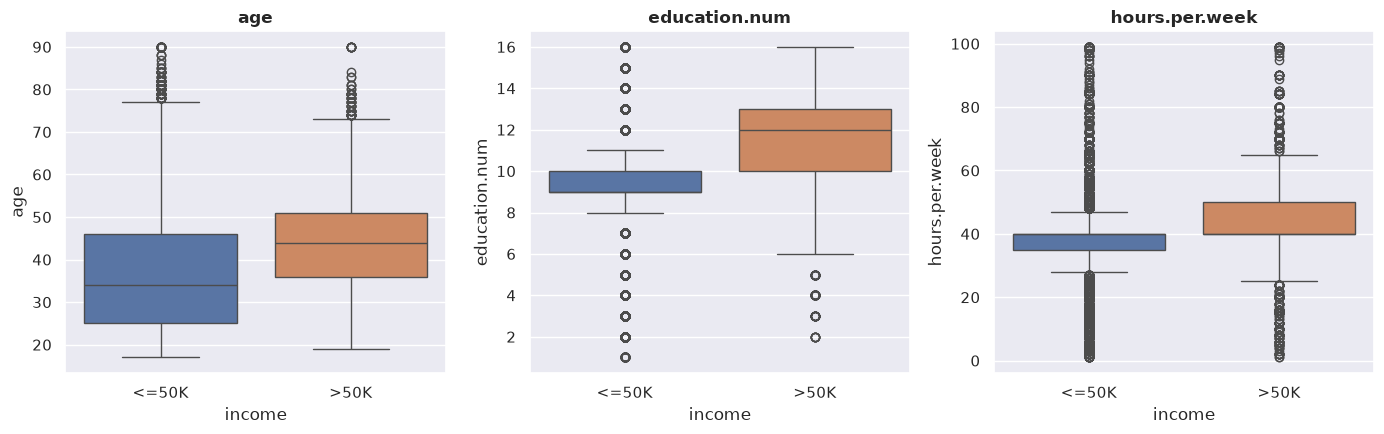

,age,education.num,hours.per.week
income,,,
<=50K,34.0,9.0,40.0
>50K,44.0,12.0,40.0


In [18]:
# Numeric columns by income
cols = ["age", "education.num", "hours.per.week"]
order = ["<=50K", ">50K"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x=TARGET, y=c, order=order, hue=TARGET, hue_order=order,
                palette=COLORS, legend=False, ax=ax)
    ax.set_title(c, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_numeric_by_income.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby(TARGET)[cols].median()

**Figure 3.** 
- Median age is 34 for `<=50K` and 44 
- for `>50K`; median `education.num` is 9 and 12. 
- Median `hours.per.week` is 40 in both groups, but the `>50K` box reaches higher.

- Distributions overlap strongly for age and hours.

In [19]:
# Skewness of capital gain and capital loss
for c in ["capital.gain", "capital.loss"]:
    print(f"{c}: {(df[c] == 0).mean():.1%} of rows are zero")

print(df[["capital.gain", "capital.loss"]].replace(0, np.nan).describe().round(0))

flag = pd.DataFrame({
    "gain>0": y_bin.groupby(df["capital.gain"] > 0).mean(),
    "loss>0": y_bin.groupby(df["capital.loss"] > 0).mean(),
}).rename(index={False: "zero", True: "non-zero"}).round(3)
flag

capital.gain: 91.7% of rows are zero
capital.loss: 95.3% of rows are zero
       capital.gain  capital.loss
count        2712.0        1519.0
mean        12939.0        1871.0
std         22395.0         377.0
min           114.0         155.0
25%          3411.0        1672.0
50%          7298.0        1887.0
75%         14084.0        1977.0
max         99999.0        4356.0


,gain>0,loss>0
zero,0.207,0.228
non-zero,0.618,0.509


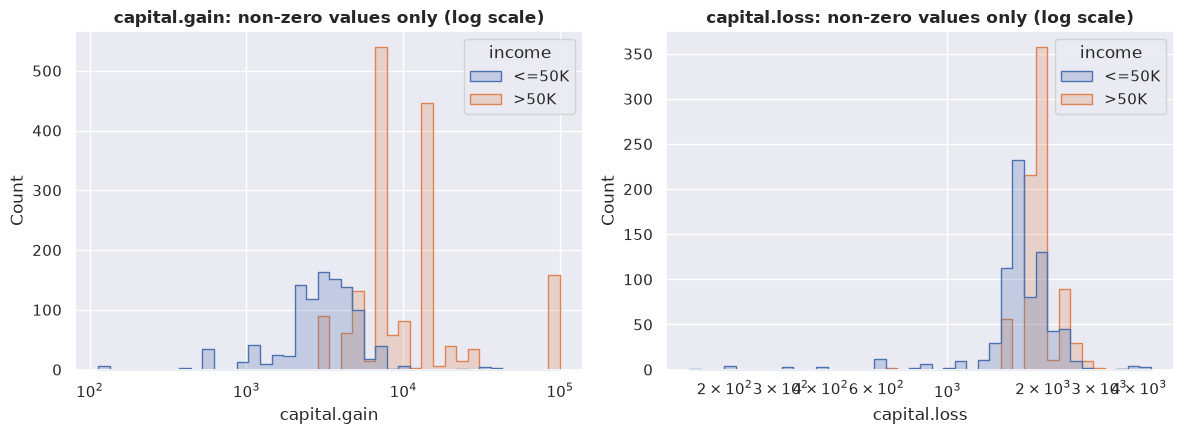

In [20]:
# Non-zero values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c in zip(axes, ["capital.gain", "capital.loss"]):
    nz = df[df[c] > 0]
    sns.histplot(data=nz, x=c, hue=TARGET, hue_order=order, palette=COLORS,
                 bins=40, log_scale=True, element="step", ax=ax)
    ax.set_title(f"{c}: non-zero values only (log scale)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_capital_skew.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 4.** 91.7% of rows have `capital.gain = 0` and 95.3% have `capital.loss = 0`.
Non-zero `capital.gain` is right-skewed (median 7298, mean 12939, max 99999). The share with
income >50K is 0.618 when `capital.gain` > 0 (0.207 when zero) and 0.509 when
`capital.loss` > 0 (0.228 when zero). 159 rows have `capital.gain = 99999`, all >50K.
No documentation explaining this value was found.

In [21]:
# Suspicious value 99999
print("capital.gain == 99999:", (df["capital.gain"] == 99999).sum(), "rows")
print(df.loc[df["capital.gain"] == 99999, TARGET].value_counts())

# the most repeated non-zero capital.gain amounts
print(df.loc[df["capital.gain"] > 0, "capital.gain"].value_counts().head(8))

capital.gain == 99999: 159 rows
income
>50K    159
Name: count, dtype: int64
capital.gain
15024    347
7688     284
7298     246
99999    159
5178      97
3103      97
4386      70
5013      69
Name: count, dtype: int64


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔧 Preprocessing</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Train_test_split</li>
<li>Pipline</li>
</ul>
</div>

In [22]:
# Drop education and target
DROP_FEATURES = ["education"]          # one-to-one with education.num

X = df.drop(columns=[TARGET] + DROP_FEATURES)
y = (df[TARGET] == ">50K").astype(int)     # 1 = high income (positive class)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X.shape, X_train.shape, X_test.shape)

print("Positive rate  full :", round(y.mean(), 4))
print("Positive rate  train:", round(y_train.mean(), 4))
print("Positive rate  test :", round(y_test.mean(), 4))
print("Positives in test set:", int(y_test.sum()))

(32537, 12) (26029, 12) (6508, 12)
Positive rate  full : 0.2409
Positive rate  train: 0.2409
Positive rate  test : 0.2409
Positives in test set: 1568


In [23]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()
print(numeric_features)
print(categorical_features)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


In [24]:
print("NaN in X_train before preprocessing:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Xt = preprocess.fit_transform(X_train)
Xt_dense = Xt.toarray() if hasattr(Xt, "toarray") else Xt
print("Transformed train shape:", Xt.shape)
print("NaN left after preprocessing:", int(np.isnan(Xt_dense).sum()))

imp = preprocess.named_transformers_["cat"].named_steps["imputer"]
print("Fill values learned from train:", dict(zip(categorical_features, imp.statistics_)))

NaN in X_train before preprocessing:
workclass         1472
occupation        1478
native.country     469
dtype: int64
Transformed train shape: (26029, 87)
NaN left after preprocessing: 0
Fill values learned from train: {'workclass': 'Private', 'marital.status': 'Married-civ-spouse', 'occupation': 'Prof-specialty', 'relationship': 'Husband', 'race': 'White', 'sex': 'Male', 'native.country': 'United-States'}


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🤖 Model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Cross validation</li>
<li>Training Model: Logistic Regression</li>
<li>Training Model: Gradient Bossting</li>
<li>Training Model: Random Forest</li>
<li>XGBoost</li>
</ul>
</div>

In [25]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print("Negatives:", neg, "| Positives:", pos, "| neg/pos:", round(neg / pos, 3))

def make(model):
    return Pipeline([("prep", preprocess), ("model", model)])

models = {
    # "Dummy (majority)": make(DummyClassifier(strategy="prior")),
    
    "LogReg": make(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    
    "Gradient Descent": make(GradientBoostingClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE)),
    
    "Random Forest": make(RandomForestClassifier(n_estimators=300, max_depth=9, max_features='sqrt', class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
    
    "XGBoost": make(XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5, scale_pos_weight=float(neg / pos), n_jobs=-1, random_state=RANDOM_STATE)),
}

scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1",
           "recall": "recall", "precision": "precision"}

Negatives: 19758 | Positives: 6271 | neg/pos: 3.151


In [26]:
rows = []
for name, model in models.items():
    t0 = time.time()
    cv = cross_validate(model, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    row = {'model': name}
    for k in scoring:
        row[k] = cv[f"test_{k}"].mean()
    row['pr_auc_std'] = cv['test_pr_auc'].std()
    row["time_s"] = time.time() - t0
    rows.append(row)
    print(f"{name:20s} done in {row['time_s']:.0f}s")

cv_results = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
cv_results.round(3)

LogReg               done in 1s
Gradient Descent     done in 21s
Random Forest        done in 7s
XGBoost              done in 340s


,pr_auc,roc_auc,f1,recall,precision,pr_auc_std,time_s
model,,,,,,,
XGBoost,0.832,0.930,0.718,0.867,0.613,0.006,340.034
Gradient Descent,0.830,0.930,0.716,0.662,0.780,0.006,21.128
Random Forest,0.776,0.909,0.660,0.888,0.525,0.011,6.607
LogReg,0.762,0.906,0.682,0.849,0.569,0.007,0.914


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">Test Evaluation</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1: Candidates and Criteria at the 0.5 Threshold | Precision-recall curve</li>
<li>Step 2: Threshold of out-of-fold predictions</li>
<li>Step 3: confusion_matrix</li>
<li>Step 4: Importance of Features</li>
</ul>
</div>

['prep', 'model']
No-skill PR-AUC (positive rate): 0.241


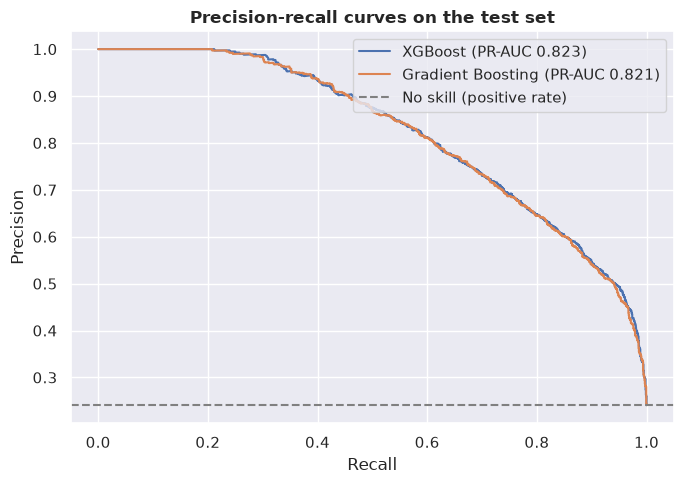

In [31]:
# Step 1: Candidates and Criteria at the 0.5 Threshold | Precision-recall curve
finalists = {
    "XGBoost": clone(models["XGBoost"]).fit(X_train, y_train),
    "Gradient Boosting": clone(models["Gradient Descent"]).fit(X_train, y_train),
}
print(list(finalists["XGBoost"].named_steps))      # expected: ['prep', 'model']

test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in finalists.items()}

rows = []
for n, p in test_proba.items():
    pred = (p >= 0.5).astype(int)
    rows.append({"model": n,
                 "pr_auc": average_precision_score(y_test, p),
                 "roc_auc": roc_auc_score(y_test, p),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred)})
test_at_05 = pd.DataFrame(rows).set_index("model").round(3)
print("No-skill PR-AUC (positive rate):", round(y_test.mean(), 3))
test_at_05

# Precision-recall curve 
fig, ax = plt.subplots(figsize=(7, 5))
for n, p in test_proba.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{n} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="No skill (positive rate)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves on the test set", fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_pr_curves_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# Step 2: Threshold of out-of-fold predictions
oof = {n: cross_val_predict(m, X_train, y_train, cv=skf, method="predict_proba", n_jobs=1)[:, 1]
       for n, m in finalists.items()}

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    i = f1.argmax()
    return thr[i], f1[i]

thresholds, rows = {}, []
for n in finalists:
    thr, f1_oof = best_f1_threshold(y_train, oof[n])
    thresholds[n] = thr
    pred_test = (test_proba[n] >= thr).astype(int)
    rows.append({"model": n, "threshold": thr, "f1_out_of_fold": f1_oof,
                 "f1_test": f1_score(y_test, pred_test),
                 "precision_test": precision_score(y_test, pred_test),
                 "recall_test": recall_score(y_test, pred_test)})
threshold_table = pd.DataFrame(rows).set_index("model").round(3)
threshold_table

,threshold,f1_out_of_fold,f1_test,precision_test,recall_test
model,,,,,
XGBoost,0.662,0.735,0.720,0.702,0.740
Gradient Boosting,0.362,0.734,0.715,0.687,0.746


In [33]:
# Step3: Confusion Matrix
for n in finalists:
    pred = (test_proba[n] >= thresholds[n]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{n} (threshold {thresholds[n]:.3f})")
    print(f"  high earners caught (TP): {tp}   missed (FN): {fn}")
    print(f"  false alarms (FP): {fp}   correctly low (TN): {tn}\n")

XGBoost (threshold 0.662)
  high earners caught (TP): 1160   missed (FN): 408
  false alarms (FP): 493   correctly low (TN): 4447

Gradient Boosting (threshold 0.362)
  high earners caught (TP): 1169   missed (FN): 399
  false alarms (FP): 533   correctly low (TN): 4407



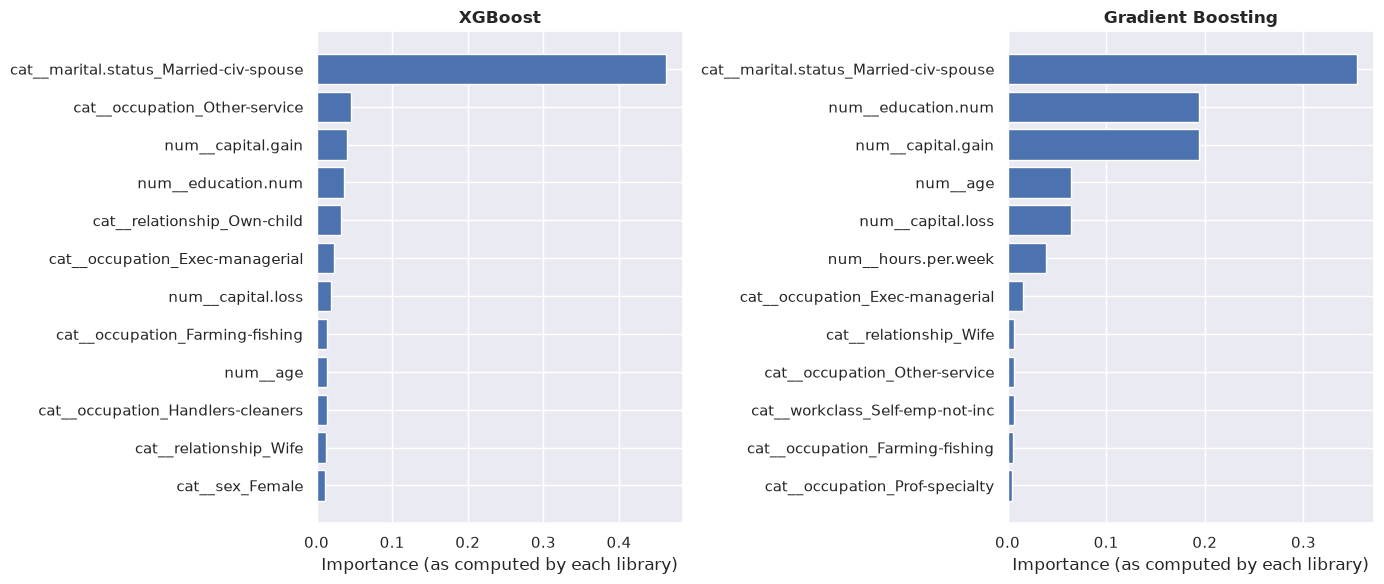

In [34]:
# Step4: Importance of Features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (n, m) in zip(axes, finalists.items()):
    names = m.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(m.named_steps["model"].feature_importances_,
                    index=names).sort_values().tail(12)
    ax.barh(imp.index, imp.values, color="#4C72B0")
    ax.set_title(n, fontweight="bold")
    ax.set_xlabel("Importance (as computed by each library)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">Final Model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1:Saved Model</li>
<li>Step 2:Reload and check the result</li>
<li>Step 3:A simple function for using the model</li>
</ul>
</div>

In [43]:
# Step 1:Saved Model
MODEL_PATH = Path("../models/adult_income_xgboost.joblib")

final_model = finalists["XGBoost"]            # fitted on the training set only
final_threshold = float(thresholds["XGBoost"])
p_test = test_proba["XGBoost"]
pred_test = (p_test >= final_threshold).astype(int)

artifact = {
    "model": final_model,
    "threshold": final_threshold,
    "features": list(X_train.columns),
    "positive_label": ">50K",
    "test_metrics": {
        "pr_auc": float(average_precision_score(y_test, p_test)),
        "roc_auc": float(roc_auc_score(y_test, p_test)),
        "precision": float(precision_score(y_test, pred_test)),
        "recall": float(recall_score(y_test, pred_test)),
        "f1": float(f1_score(y_test, pred_test)),
    },
    "versions": {
        "python": sys.version.split()[0],
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
    },
}
joblib.dump(artifact, MODEL_PATH, compress=3)
print("Saved:", MODEL_PATH.resolve())
print(f"File size: {MODEL_PATH.stat().st_size / 1e6:.2f} MB")

Saved: /home/isapour/project/adult-census-income/models/adult_income_xgboost.joblib
File size: 0.18 MB


In [44]:
# Step 2:Reload and check the result
art = joblib.load(MODEL_PATH)

proba_reload = art["model"].predict_proba(X_test[art["features"]])[:, 1]
pred_reload = (proba_reload >= art["threshold"]).astype(int)

print("Same probabilities as before saving:", np.allclose(proba_reload, p_test))
print("Threshold:", round(art["threshold"], 3))
print("precision:", round(precision_score(y_test, pred_reload), 3),
      "| recall:", round(recall_score(y_test, pred_reload), 3),
      "| f1:", round(f1_score(y_test, pred_reload), 3))
print(art["versions"])

Same probabilities as before saving: True
Threshold: 0.662
precision: 0.702 | recall: 0.74 | f1: 0.72
{'python': '3.12.16', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'pandas': '3.1.0'}


In [45]:
# Step 3:A simple function for using the model

def predict_income(people, artifact):
    """people: DataFrame with the same columns as the training features.
    Missing values must be np.nan (not '?')."""
    X_new = people[artifact["features"]]
    proba = artifact["model"].predict_proba(X_new)[:, 1]
    return pd.DataFrame({
        "probability_high_income": proba.round(3),
        "prediction": np.where(proba >= artifact["threshold"], ">50K", "<=50K"),
    }, index=people.index)

sample = X_test.iloc[:3]
out = predict_income(sample, art)
out["actual"] = np.where(y_test.iloc[:3] == 1, ">50K", "<=50K")
out

,probability_high_income,prediction,actual
21102,0.456,<=50K,<=50K
21469,0.772,>50K,>50K
20815,0.776,>50K,<=50K


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
padding:35px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
text-align:center;
">

<h1 style="margin-bottom:10px;color:#00E5FF;">🎉 Thank You for rewied</h1>
<hr style="border:1px solid #8A2BE2;opacity:.4;width:70%;margin:auto;">

<br>

<h3 style="color:#E0E0E0;">Thank you for taking the time to explore this notebook.</h3>
<h5 style="font-size:17px;line-height:1.8;color:#CFCFCF;margin-top:20px;">
I hope this project has been useful and informative.<br>
Your feedback and suggestions are always appreciated.</h5>

<br>

<h2 style="color:#00E5FF;">Code • Learn • Build</h2>
</div>